# MANE 4961: Engineering with Machine Learning — Homework 5, Problem 2

**Name:** Soumyanil Sadhu Deep
**RIN:** 662110663

Support vector machines for the breast cancer Wisconsin dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42

## Problem 2: SVM classification of the breast cancer Wisconsin dataset

Only three features are used: **worst compactness**, **worst concavity** and **worst area**. Target: 0 = malignant, 1 = benign.

The data are split 70% / 30% into training and test sets (stratified, `random_state=42`). The features have very different scales (worst area is in the hundreds to thousands, the other two are below 1.3), and SVMs are distance-based, so the features are standardized inside a pipeline with a scaler fitted on the training data only. Accuracy is reported on the test set; 5-fold cross-validation on the training set is also shown as a check that the result doesn't depend on one lucky split.

In [2]:
data = load_breast_cancer()
features = ['worst compactness', 'worst concavity', 'worst area']
idx = [list(data.feature_names).index(f) for f in features]
X = data.data[:, idx]
y = data.target

df = pd.DataFrame(X, columns=features)
df['diagnosis'] = np.where(y == 0, 'malignant', 'benign')
print('Samples:', X.shape[0], '| features:', features)
print(df['diagnosis'].value_counts().to_string(), '\n')
df.groupby('diagnosis')[features].describe().T.round(3)

Samples: 569 | features: ['worst compactness', 'worst concavity', 'worst area']
diagnosis
benign       357
malignant    212 



diagnosis                  benign  malignant
worst compactness count   357.000    212.000
                  mean      0.183      0.375
                  std       0.092      0.170
                  min       0.027      0.051
                  25%       0.112      0.244
                  50%       0.170      0.356
                  75%       0.230      0.448
                  max       0.585      1.058
worst concavity   count   357.000    212.000
                  mean      0.166      0.451
                  std       0.140      0.182
                  min       0.000      0.024
                  25%       0.077      0.326
                  50%       0.141      0.405
                  75%       0.222      0.556
                  max       1.252      1.170
worst area        count   357.000    212.000
                  mean    558.899   1422.286
                  std     163.601    597.968
                  min     185.200    508.100
                  25%     447.100    970.300
                  50%     547.400   1303.000
                  75%     670.000   1712.750
                  max    1210.000   4254.000

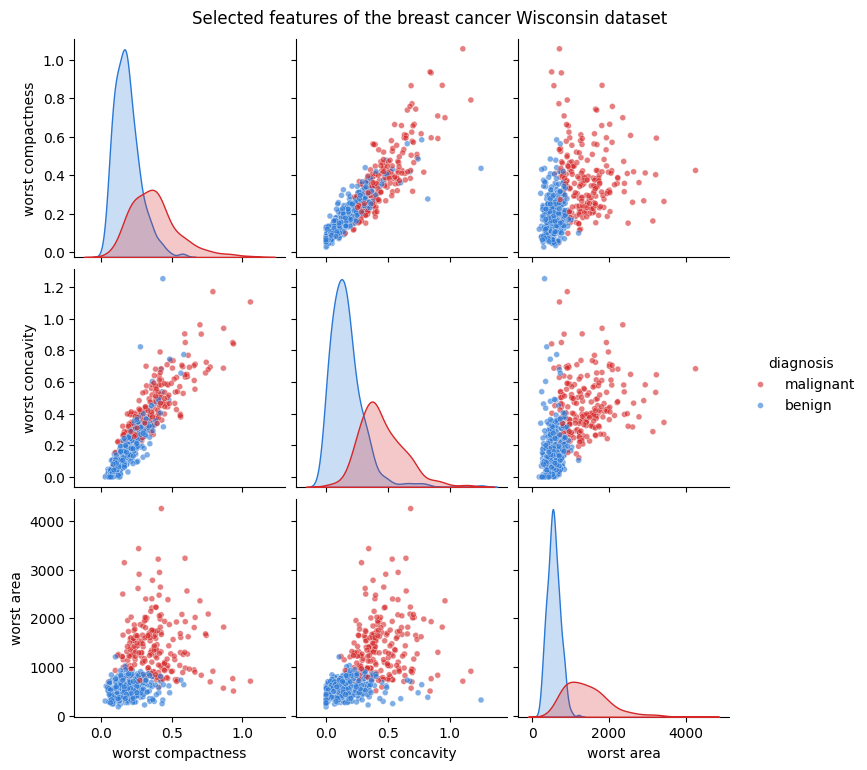

In [3]:
g = sns.pairplot(df, hue='diagnosis', hue_order=['malignant', 'benign'], palette=['#d62728', '#2a78d6'],
                 plot_kws={'s': 18, 'alpha': 0.6})
g.figure.suptitle('Selected features of the breast cancer Wisconsin dataset', y=1.02)
plt.show()

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print('Training samples:', len(X_tr), ' Test samples:', len(X_te))

models = {
    'Linear kernel': make_pipeline(StandardScaler(), SVC(kernel='linear')),
    'RBF kernel, C = 2': make_pipeline(StandardScaler(), SVC(kernel='rbf', C=2)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = {}
for name, clf in models.items():
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    cv_scores = cross_val_score(clf, X_tr, y_tr, cv=cv)
    results[name] = {'test accuracy': accuracy_score(y_te, y_pred),
                     'train accuracy': accuracy_score(y_tr, clf.predict(X_tr)),
                     '5-fold CV accuracy (train)': cv_scores.mean(),
                     'CV std': cv_scores.std(),
                     'support vectors': int(clf[-1].n_support_.sum())}
    print(f'\n{name}: test accuracy = {results[name]["test accuracy"]:.4f}')
    print(classification_report(y_te, y_pred, target_names=data.target_names, digits=4))

pd.DataFrame(results).T.round(4)

Training samples: 398  Test samples: 171

Linear kernel: test accuracy = 0.9357
              precision    recall  f1-score   support

   malignant     0.9344    0.8906    0.9120        64
      benign     0.9364    0.9626    0.9493       107

    accuracy                         0.9357       171
   macro avg     0.9354    0.9266    0.9307       171
weighted avg     0.9356    0.9357    0.9353       171


RBF kernel, C = 2: test accuracy = 0.9357
              precision    recall  f1-score   support

   malignant     0.9206    0.9062    0.9134        64
      benign     0.9444    0.9533    0.9488       107

    accuracy                         0.9357       171
   macro avg     0.9325    0.9298    0.9311       171
weighted avg     0.9355    0.9357    0.9356       171



,test accuracy,train accuracy,5-fold CV accuracy (train),CV std,support vectors
Linear kernel,0.9357,0.9497,0.9497,0.0140,61.0
"RBF kernel, C = 2",0.9357,0.9573,0.9548,0.0061,72.0


### 2(i) and 2(ii) Accuracies

2(i)  Linear-kernel SVM accuracy (test set)   : 0.9357
2(ii) RBF-kernel SVM (C = 2) accuracy (test set): 0.9357


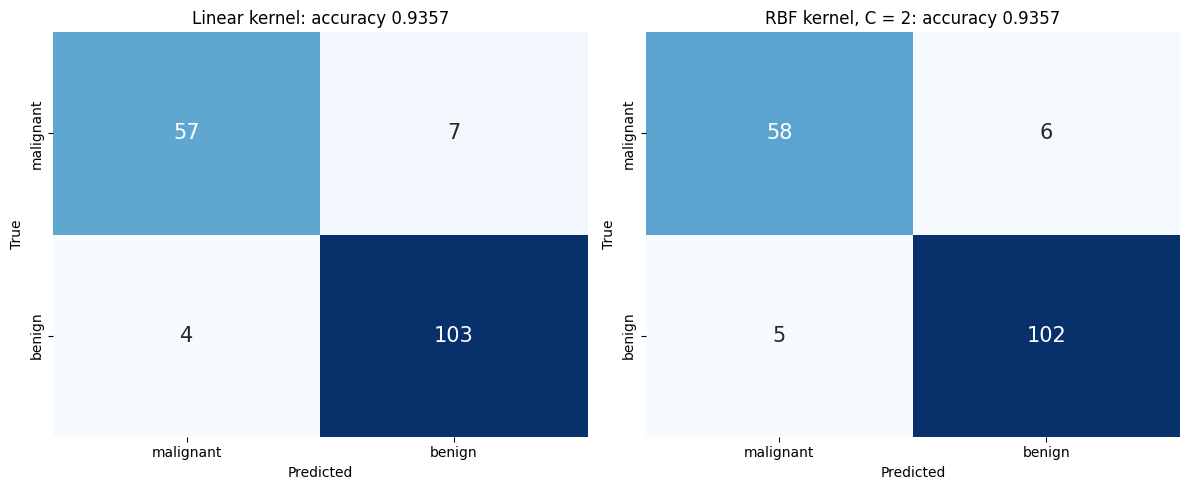

In [5]:
print(f"2(i)  Linear-kernel SVM accuracy (test set)   : {results['Linear kernel']['test accuracy']:.4f}")
print(f"2(ii) RBF-kernel SVM (C = 2) accuracy (test set): {results['RBF kernel, C = 2']['test accuracy']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, clf) in zip(axes, models.items()):
    cm = confusion_matrix(y_te, clf.predict(X_te))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 15},
                xticklabels=data.target_names, yticklabels=data.target_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f"{name}: accuracy {results[name]['test accuracy']:.4f}")
plt.tight_layout()
plt.show()

In [6]:
# For reference: the same models without feature scaling
for name, clf in [('Linear kernel', SVC(kernel='linear')), ('RBF kernel, C = 2', SVC(kernel='rbf', C=2))]:
    clf.fit(X_tr, y_tr)
    print(f'{name} without scaling: test accuracy = {accuracy_score(y_te, clf.predict(X_te)):.4f}')

Linear kernel without scaling: test accuracy = 0.9123
RBF kernel, C = 2 without scaling: test accuracy = 0.9240
